# Step 1: Data collection

# Step 2: Data Preprocessing


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
# Define paths
ANNOTATIONS_DIR = "/content/drive/MyDrive/internProject/annotations"
IMAGES_DIR = "/content/drive/MyDrive/internProject/images"
OUTPUT_DIR = "outputs"

In [3]:
# Create necessary directories
import os

os.makedirs(os.path.join(OUTPUT_DIR, 'images', 'train'), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, 'images', 'val'), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, 'labels', 'train'), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, 'labels', 'val'), exist_ok=True)

In [ ]:
# reading all XML annotation files in a folder, 
# extracts each image’s filename and the objects in it (with class names and bounding box coordinates), and stores everything in a list.
import xml.etree.ElementTree as ET

annotations = []
for xml_file in os.listdir(ANNOTATIONS_DIR):
    tree = ET.parse(os.path.join(ANNOTATIONS_DIR, xml_file))
    root = tree.getroot()
    file_name = root.find('filename').text
    objects = []
    for obj in root.findall('object'):
        class_name = obj.find('name').text
        bndbox = obj.find('bndbox')
        xmin = int(bndbox.find('xmin').text)
        ymin = int(bndbox.find('ymin').text)
        xmax = int(bndbox.find('xmax').text)
        ymax = int(bndbox.find('ymax').text)
        objects.append((class_name, xmin, ymin, xmax, ymax))
    annotations.append((file_name, objects))

In [5]:
# Split dataset into training and validation sets
train_annotations = annotations[:int(0.8*len(annotations))]
val_annotations = annotations[int(0.8*len(annotations)):]

In [6]:
# Encode labels
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
all_labels = [obj[0] for ann in annotations for obj in ann[1]]
label_encoder.fit(all_labels)

LabelEncoder()

In [ ]:
# Helper function to convert annotations(bounding box) to YOLO format
def convert_to_yolo_format(size, box):
    dw = 1./size[0]
    dh = 1./size[1]
    x = (box[0] + box[2]) / 2.0
    y = (box[1] + box[3]) / 2.0
    w = box[2] - box[0]
    h = box[3] - box[1]
    x = x*dw
    w = w*dw
    y = y*dh
    h = h*dh
    return (x,y,w,h)

In [ ]:
# Save images and labels in YOLO format
import shutil
import cv2

def save_yolo_files(annotations, image_dir, label_dir):
    for file_name, objects in annotations:
        img_path = os.path.join(IMAGES_DIR, file_name)
        img = cv2.imread(img_path)
        h, w, _ = img.shape
        shutil.copy(img_path, image_dir)
        label_path = os.path.join(label_dir, file_name.replace('.png', '.txt'))
        with open(label_path, 'w') as f:
            for obj in objects:
                class_name, xmin, ymin, xmax, ymax = obj
                class_id = label_encoder.transform([class_name])[0]
                bb = convert_to_yolo_format((w, h), (xmin, ymin, xmax, ymax))
                f.write(f"{class_id} {' '.join(map(str, bb))}\n")

# Save train and val data
save_yolo_files(train_annotations, os.path.join(OUTPUT_DIR, 'images', 'train'), os.path.join(OUTPUT_DIR, 'labels', 'train'))
save_yolo_files(val_annotations, os.path.join(OUTPUT_DIR, 'images', 'val'), os.path.join(OUTPUT_DIR, 'labels', 'val'))

In [ ]:
# Create data.yaml file: tells YOLO where the dataset is located and how to interpret the labels during training.
data_yaml = f"""
train: {os.path.join(OUTPUT_DIR, 'images', 'train')}
val: {os.path.join(OUTPUT_DIR, 'images', 'val')}

nc: {len(label_encoder.classes_)}
names: {label_encoder.classes_.tolist()}
"""

with open(os.path.join(OUTPUT_DIR, 'data.yaml'), 'w') as f:
    f.write(data_yaml)

# Step 3: Model Selection: YOLOv8


# Step 4: Load the YOLOv8 model from ultralytics library

In [ ]:
# Load YOLOv8 model

from ultralytics import YOLO
model = YOLO('yolov8n.pt')

# Step 5: Train the YOLOv8 model


In [12]:
model.train(data=os.path.join(OUTPUT_DIR, 'data.yaml'), epochs=50, imgsz=416, batch=16, cache=True)

Ultralytics 8.3.241 🚀 Python-3.12.12 torch-2.9.0+cpu CPU (AMD EPYC 7B13)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/internProject/outputs/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plot

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c522f7448f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

# Step 6: Model Performance Visualization

In [ ]:
# Load the best model
model = YOLO('runs/detect/train/weights/best.pt')

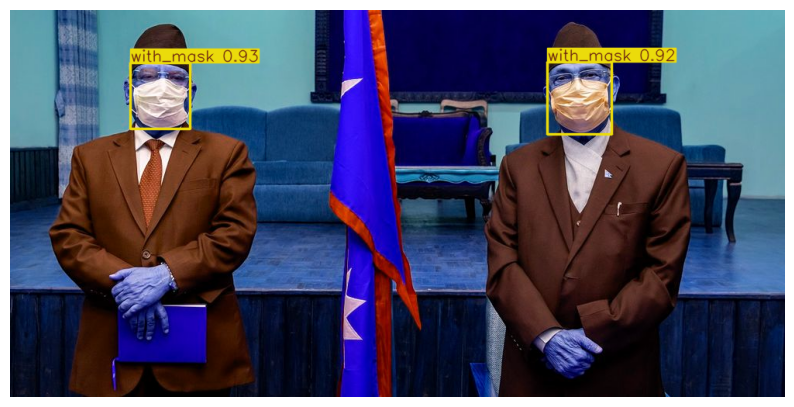

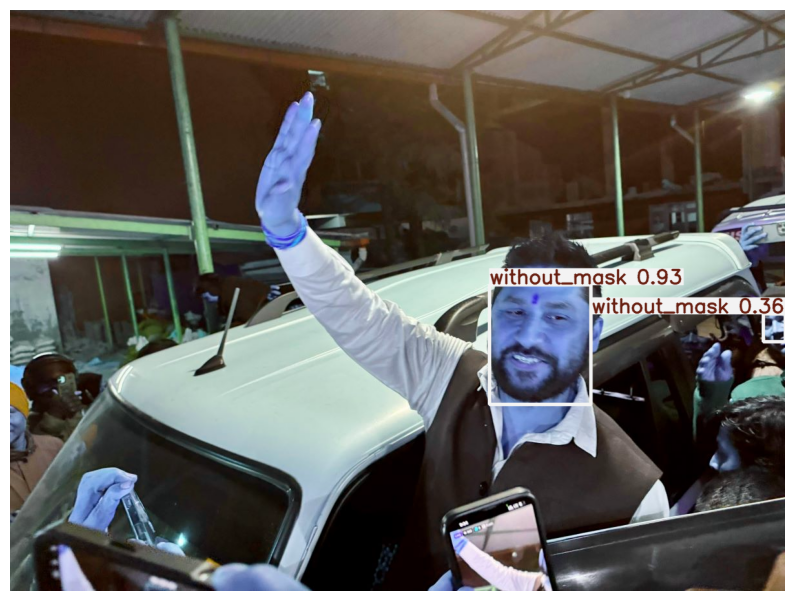

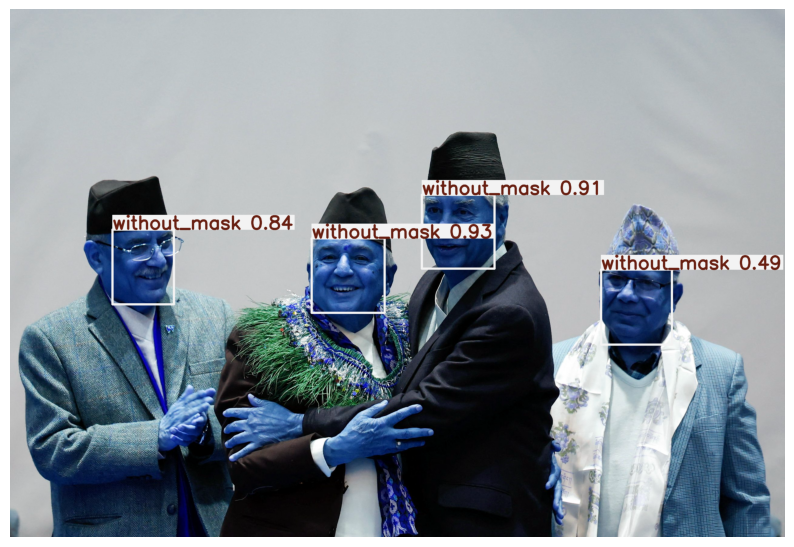

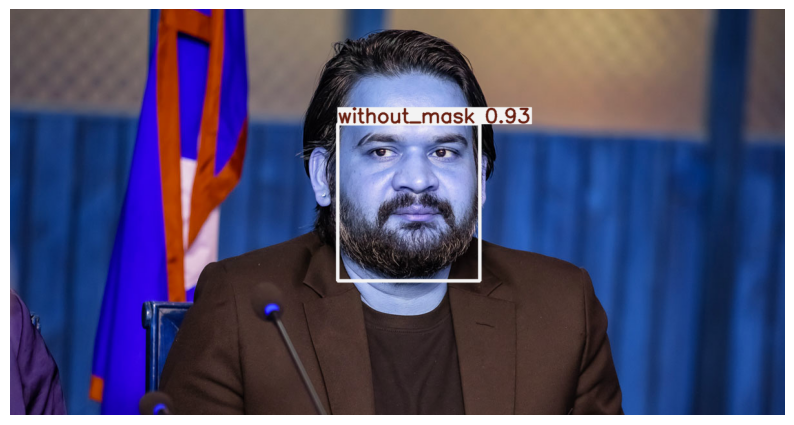

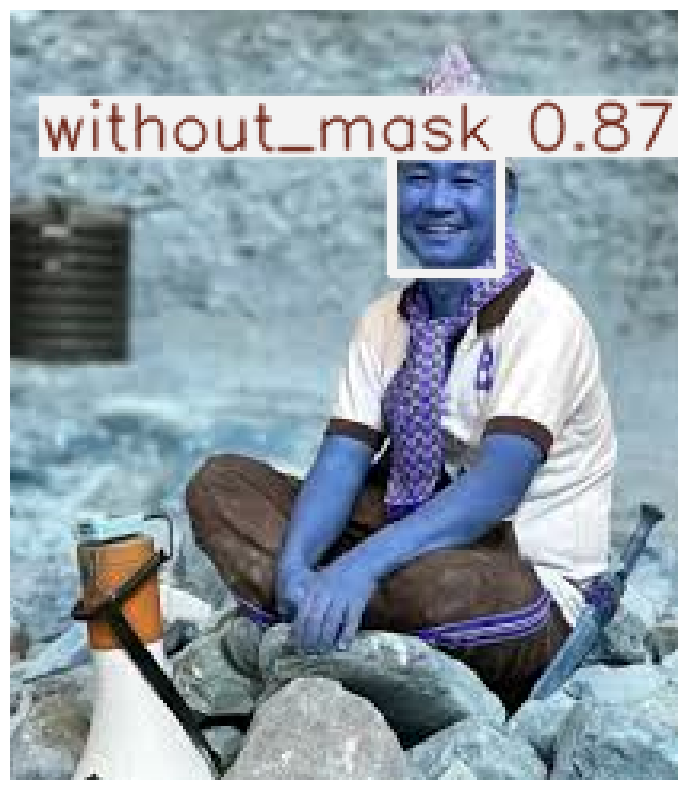

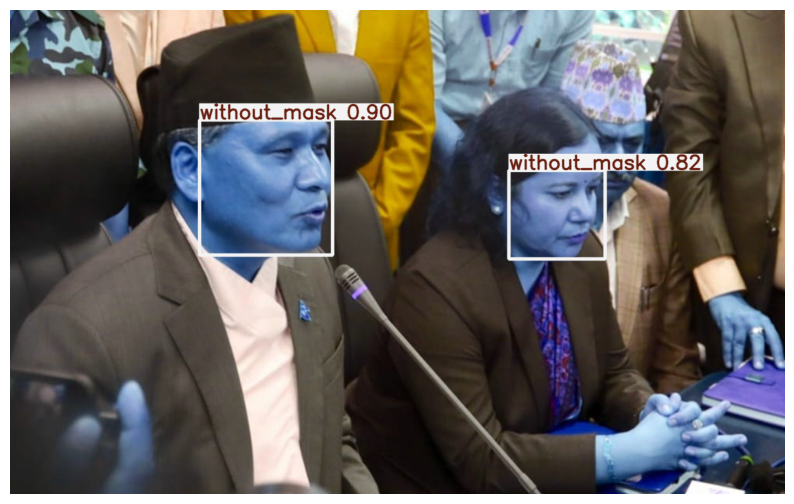

WARNING 'source' is missing. Using 'source=D:\python\Lib\site-packages\ultralytics\assets'.


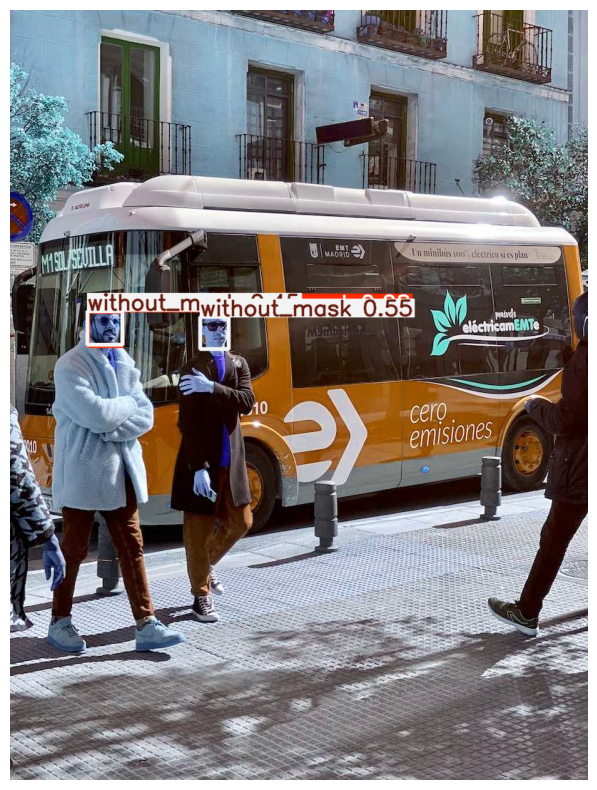

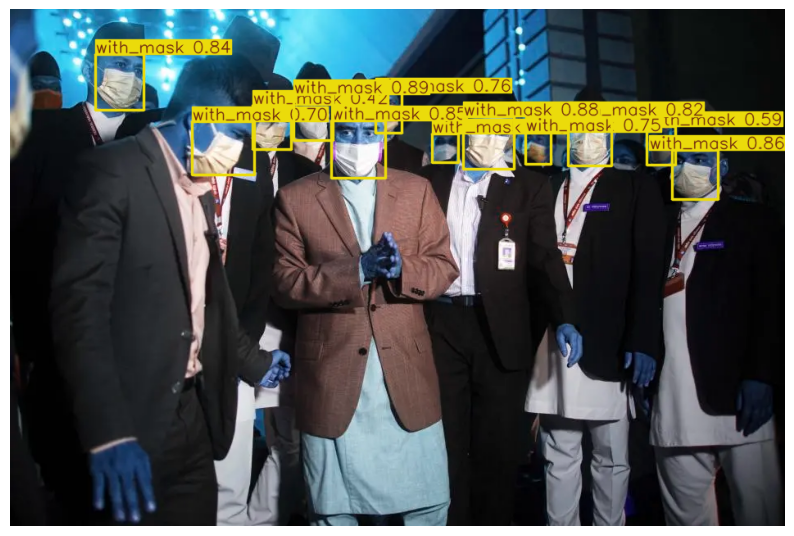

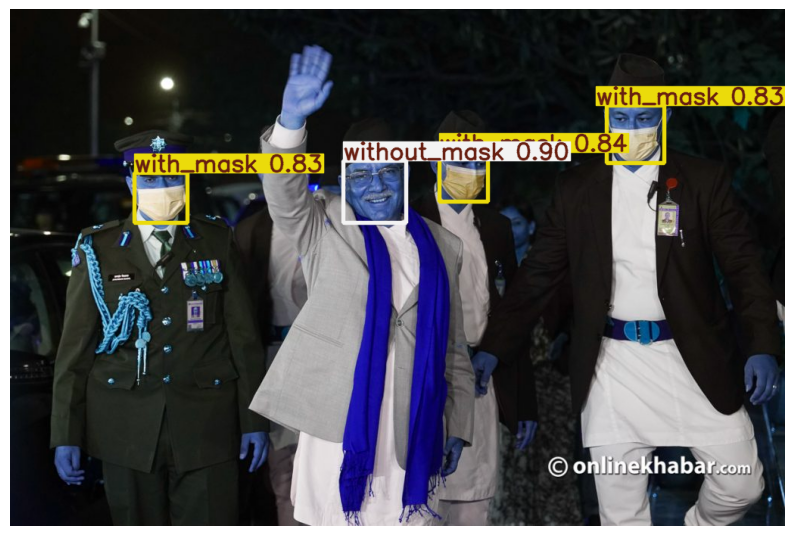

In [3]:
# Display sample images with detections
import matplotlib.pyplot as plt

def plot_sample_images(image_dir, model, num_images=20):
    images = [os.path.join(image_dir, img) for img in os.listdir(image_dir)][:num_images]
    for img_path in images:
        img = cv2.imread(img_path)
        results = model(img)
        result_img = results[0].plot()  # Plot results on the image
        plt.figure(figsize=(10, 10))
        plt.imshow(result_img)
        plt.axis('off')
        plt.show()

plot_sample_images(os.path.join(OUTPUT_DIR, 'images', 'test'), model)

In [1]:
# Path to the model weights file
import os
import cv2
from ultralytics import YOLO
model_weights_path = 'C:\\Users\\alyoh\\OneDrive\\Desktop\\Projects\\internProject\\runs\\detect\\train\\weights\\best.pt'

# Verify if the model weights file exists at the specified path
if not os.path.exists(model_weights_path):
    print(f"Error: Model weights not found at {model_weights_path}. Please update 'model_weights_path' to the correct location of your downloaded 'best.pt' file.")
    exit()

# Load your custom trained model
model = YOLO(model_weights_path)

# Initialize webcam capture
# 0 typically refers to the default webcam. Change if you have multiple cameras.
cap = cv2.VideoCapture(0)

# Check if webcam opened successfully
if not cap.isOpened():
    print("Error: Could not open webcam.")
    exit()

print("Webcam opened successfully. Press 'q' to quit.")

while True:
    ret, frame = cap.read() # Read a frame from the webcam

    if not ret:
        print("Failed to grab frame.")
        break

    # Perform inference on the captured frame
    results = model(frame, verbose=False) # verbose=False to suppress print statements for each frame

    # Display results on the frame
    # The .plot() method draws bounding boxes and labels directly on the image
    annotated_frame = results[0].plot()

    # Display the annotated frame
    cv2.imshow('YOLOv8 Real-time Inference', annotated_frame)

    # Break the loop if 'q' key is pressed
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Release the webcam and destroy all OpenCV windows
cap.release()
cv2.destroyAllWindows()
print("Webcam released and windows closed.")


Webcam opened successfully. Press 'q' to quit.
Webcam released and windows closed.
